# LSTM Baseline for Vital Sign Forecasting

This notebook implements a standard **LSTM model** for vital sign forecasting as a baseline comparison to the **Diffusion Model** approach.

## Key Differences from Diffusion Model:
- **Deterministic**: Produces single prediction (no uncertainty)
- **Faster**: Single forward pass vs 50+ sampling steps
- **Simpler**: Standard sequence-to-sequence architecture

## Task:
Given 42 hours of patient vitals, predict the next 6 hours (same as diffusion model)

In [21]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# Configuration (IMPROVED for better performance)
# ==========================================
CONFIG = {
    "DATA_PATH": "./training_setA",
    "VITALS": ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp'],
    "SEQ_LEN": 48,       # Total window (48 hours)
    "PRED_LEN": 6,       # Predict 6 hours ahead
    "BATCH_SIZE": 64,    # ↑ Increased for stability
    "HIDDEN_DIM": 256,   # ↑ Increased capacity
    "NUM_LAYERS": 3,     # ↑ Deeper network
    "EPOCHS": 50,        # ↑ More training
    "MAX_FILES": 3000,
    "LEARNING_RATE": 5e-4,  # ↓ Lower for stability
    "DROPOUT": 0.3,      # ↑ More regularization
    "WEIGHT_DECAY": 1e-5,  # L2 regularization
    "TEACHER_FORCING_RATIO": 0.5,  # Training technique
    "USE_ATTENTION": True  # Attention mechanism
}

# Vital sign display info
VITAL_INFO = {
    'HR': {'name': 'Heart Rate', 'unit': 'bpm', 'scale': 100},
    'MAP': {'name': 'Mean Arterial Pressure', 'unit': 'mmHg', 'scale': 100},
    'O2Sat': {'name': 'Oxygen Saturation', 'unit': '%', 'scale': 100},
    'SBP': {'name': 'Systolic Blood Pressure', 'unit': 'mmHg', 'scale': 140},
    'Resp': {'name': 'Respiratory Rate', 'unit': 'breaths/min', 'scale': 20}
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"\n✓ Improved Configuration:")
print(f"  Hidden Dim: {CONFIG['HIDDEN_DIM']}")
print(f"  Layers: {CONFIG['NUM_LAYERS']}")
print(f"  Attention: {CONFIG['USE_ATTENTION']}")
print(f"  Teacher Forcing: {CONFIG['TEACHER_FORCING_RATIO']}")

Using device: cpu

✓ Improved Configuration:
  Hidden Dim: 256
  Layers: 3
  Attention: True
  Teacher Forcing: 0.5


## 1. Dataset Loader (Same as Diffusion Model)

In [22]:
class SepsisDataset(Dataset):
    def __init__(self, data_dir, config, mode='train'):
        self.files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
        self.files = self.files[:config["MAX_FILES"]]
        self.data_dir = data_dir
        self.vitals = config["VITALS"]
        self.seq_len = config["SEQ_LEN"]
        self.pred_len = config["PRED_LEN"]
        self.input_len = self.seq_len - self.pred_len  # 42 hours input
        self.data_cache = []

        print(f"Loading {len(self.files)} patients for {mode}...")

        for f in self.files:
            df = pd.read_csv(os.path.join(data_dir, f), sep='|')
            df = df[self.vitals]
            
            # Handle missing data
            df = df.ffill().bfill().fillna(0)
            
            # Normalize
            norm_vals = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}
            for v in self.vitals:
                df[v] = df[v] / norm_vals[v]

            data = df.values.astype(np.float32)

            # Create sliding windows
            if len(data) >= self.seq_len:
                for i in range(0, len(data) - self.seq_len + 1, 12):
                    window = data[i : i + self.seq_len]
                    self.data_cache.append(window)

        self.data_cache = np.array(self.data_cache)
        print(f"Created {len(self.data_cache)} windows of shape {self.data_cache.shape}")

    def __len__(self):
        return len(self.data_cache)

    def __getitem__(self, idx):
        window = self.data_cache[idx]  # (seq_len, channels)
        
        # Split into input (past) and target (future)
        x = window[:self.input_len]   # (42, 5) - input sequence
        y = window[self.input_len:]   # (6, 5)  - target sequence
        
        return torch.tensor(x), torch.tensor(y)

## 2. LSTM Model Architecture

In [23]:
class Attention(nn.Module):
    """
    Bahdanau-style attention mechanism for sequence-to-sequence models.
    """
    def __init__(self, encoder_dim, decoder_dim):
        super().__init__()
        self.attn = nn.Linear(encoder_dim + decoder_dim, decoder_dim)
        self.v = nn.Linear(decoder_dim, 1, bias=False)
    
    def forward(self, hidden, encoder_outputs):
        """
        hidden: (batch, decoder_dim) - decoder hidden state
        encoder_outputs: (batch, seq_len, encoder_dim)
        returns: context vector (batch, encoder_dim)
        """
        seq_len = encoder_outputs.size(1)
        
        # Repeat hidden for each timestep
        hidden = hidden.unsqueeze(1).repeat(1, seq_len, 1)  # (batch, seq_len, decoder_dim)
        
        # Compute attention energies
        energy = torch.tanh(self.attn(torch.cat([hidden, encoder_outputs], dim=2)))
        attention = self.v(energy).squeeze(2)  # (batch, seq_len)
        
        # Softmax to get attention weights
        weights = torch.softmax(attention, dim=1)  # (batch, seq_len)
        
        # Weighted sum of encoder outputs
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)
        
        return context, weights


class LSTMForecaster(nn.Module):
    """
    IMPROVED LSTM with:
    1. Bidirectional encoder
    2. Attention mechanism  
    3. Layer normalization
    4. Residual connections
    5. Multi-head output projection
    """
    def __init__(self, num_features, hidden_dim, num_layers, pred_len, dropout=0.2, use_attention=True):
        super().__init__()
        
        self.num_features = num_features
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.pred_len = pred_len
        self.use_attention = use_attention
        
        # Encoder output dimension (bidirectional = 2x hidden)
        self.encoder_dim = hidden_dim * 2
        
        # Input projection (embedding layer)
        self.input_proj = nn.Sequential(
            nn.Linear(num_features, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, num_features)
        )
        
        # Bidirectional Encoder LSTM
        self.encoder = nn.LSTM(
            input_size=num_features,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True  # ← Key improvement
        )
        
        # Bridge: convert bidirectional hidden to unidirectional decoder
        self.bridge_h = nn.Linear(hidden_dim * 2, hidden_dim)
        self.bridge_c = nn.Linear(hidden_dim * 2, hidden_dim)
        
        # Layer norm after encoder
        self.encoder_norm = nn.LayerNorm(self.encoder_dim)
        
        # Attention mechanism
        if use_attention:
            # encoder_dim for encoder outputs, hidden_dim for decoder hidden
            self.attention = Attention(self.encoder_dim, hidden_dim)
            decoder_input_size = num_features + self.encoder_dim  # input + context
        else:
            decoder_input_size = num_features
        
        # Decoder LSTM
        self.decoder = nn.LSTM(
            input_size=decoder_input_size,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # Multi-layer output projection with residual
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_features)
        )
        
        # Skip connection for predictions
        self.skip_proj = nn.Linear(num_features, num_features)
        
    def forward(self, x, teacher_forcing_ratio=0.0, target=None):
        """
        x: (batch, seq_len, num_features) - input sequence
        teacher_forcing_ratio: probability of using ground truth as next input
        target: (batch, pred_len, num_features) - for teacher forcing
        returns: (batch, pred_len, num_features) - predicted sequence
        """
        batch_size = x.size(0)
        
        # Input projection
        x_proj = self.input_proj(x) + x  # Residual
        
        # Encode input sequence (bidirectional)
        encoder_outputs, (hidden, cell) = self.encoder(x_proj)
        # encoder_outputs: (batch, seq_len, hidden_dim * 2)
        
        # Apply layer norm
        encoder_outputs = self.encoder_norm(encoder_outputs)
        
        # Bridge bidirectional hidden states to unidirectional
        # hidden: (num_layers * 2, batch, hidden_dim)
        # Reshape to (num_layers, 2, batch, hidden_dim) then concat directions
        hidden = hidden.view(self.num_layers, 2, batch_size, self.hidden_dim)
        hidden = torch.cat([hidden[:, 0], hidden[:, 1]], dim=2)  # (num_layers, batch, hidden*2)
        hidden = self.bridge_h(hidden)  # (num_layers, batch, hidden_dim)
        
        cell = cell.view(self.num_layers, 2, batch_size, self.hidden_dim)
        cell = torch.cat([cell[:, 0], cell[:, 1]], dim=2)
        cell = self.bridge_c(cell)
        
        # Decode: use last input as first decoder input
        decoder_input = x[:, -1:, :]  # (batch, 1, features)
        
        outputs = []
        for t in range(self.pred_len):
            # Attention context
            if self.use_attention:
                # hidden[-1] is (batch, hidden_dim) - last layer's hidden state
                context, _ = self.attention(hidden[-1], encoder_outputs)
                # context is (batch, encoder_dim)
                decoder_input_with_context = torch.cat([decoder_input, context.unsqueeze(1)], dim=2)
            else:
                decoder_input_with_context = decoder_input
            
            # Decoder step
            decoder_output, (hidden, cell) = self.decoder(decoder_input_with_context, (hidden, cell))
            
            # Output projection with skip connection
            prediction = self.fc(decoder_output)
            skip = self.skip_proj(decoder_input)
            prediction = prediction + skip  # Residual from last input
            
            outputs.append(prediction)
            
            # Teacher forcing: use ground truth with some probability
            if target is not None and np.random.random() < teacher_forcing_ratio:
                decoder_input = target[:, t:t+1, :]
            else:
                decoder_input = prediction  # Autoregressive
        
        # Stack predictions
        outputs = torch.cat(outputs, dim=1)  # (batch, pred_len, features)
        return outputs

## 3. Training Loop

In [24]:
def train_lstm():
    # Load data
    dataset = SepsisDataset(CONFIG["DATA_PATH"], CONFIG)
    
    # Split into train/val (80/20)
    train_size = int(0.8 * len(dataset))
    val_size = len(dataset) - train_size
    train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])
    
    train_loader = DataLoader(train_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)
    
    print(f"\nTrain size: {train_size}, Val size: {val_size}")
    
    # Initialize improved model
    model = LSTMForecaster(
        num_features=len(CONFIG["VITALS"]),
        hidden_dim=CONFIG["HIDDEN_DIM"],
        num_layers=CONFIG["NUM_LAYERS"],
        pred_len=CONFIG["PRED_LEN"],
        dropout=CONFIG["DROPOUT"],
        use_attention=CONFIG["USE_ATTENTION"]
    ).to(device)
    
    # AdamW optimizer with weight decay
    optimizer = torch.optim.AdamW(
        model.parameters(), 
        lr=CONFIG["LEARNING_RATE"],
        weight_decay=CONFIG["WEIGHT_DECAY"]
    )
    
    # Combined loss: MSE + Smoothness penalty
    mse_loss = nn.MSELoss()
    l1_loss = nn.L1Loss()
    
    def combined_loss(pred, target):
        """MSE + L1 + Temporal smoothness penalty"""
        mse = mse_loss(pred, target)
        l1 = l1_loss(pred, target) * 0.1  # Weighted L1
        
        # Smoothness: penalize large jumps in predictions
        if pred.size(1) > 1:
            diff = pred[:, 1:] - pred[:, :-1]
            smoothness = torch.mean(diff ** 2) * 0.05
        else:
            smoothness = 0
        
        return mse + l1 + smoothness
    
    # Cosine annealing scheduler (better than ReduceLROnPlateau)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=10, T_mult=2, eta_min=1e-6
    )
    
    # Training history
    train_losses = []
    val_losses = []
    
    print("\n" + "="*60)
    print("Starting IMPROVED LSTM Training")
    print("="*60)
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"Improvements: Bidirectional Encoder, Attention, Layer Norm, Residuals")
    print("="*60 + "\n")
    
    best_val_loss = float('inf')
    patience = 10
    patience_counter = 0
    
    for epoch in range(CONFIG["EPOCHS"]):
        # Calculate teacher forcing ratio (decay over epochs)
        tf_ratio = CONFIG["TEACHER_FORCING_RATIO"] * (1 - epoch / CONFIG["EPOCHS"])
        
        # Training
        model.train()
        train_loss = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            
            optimizer.zero_grad()
            
            # Forward pass with teacher forcing
            pred = model(x, teacher_forcing_ratio=tf_ratio, target=y)
            loss = combined_loss(pred, y)
            
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        train_losses.append(train_loss)
        
        # Validation (no teacher forcing)
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                pred = model(x, teacher_forcing_ratio=0.0)  # No teacher forcing
                val_loss += combined_loss(pred, y).item()
        
        val_loss /= len(val_loader)
        val_losses.append(val_loss)
        
        scheduler.step()
        current_lr = optimizer.param_groups[0]['lr']
        
        # Early stopping check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict().copy()
            patience_counter = 0
            marker = "★ Best"
        else:
            patience_counter += 1
            marker = ""
        
        print(f"Epoch {epoch+1:2d}/{CONFIG['EPOCHS']} | Train: {train_loss:.5f} | Val: {val_loss:.5f} | LR: {current_lr:.2e} | TF: {tf_ratio:.2f} {marker}")
        
        # Early stopping
        if patience_counter >= patience:
            print(f"\n⚠ Early stopping at epoch {epoch+1} (no improvement for {patience} epochs)")
            break
    
    # Load best model
    model.load_state_dict(best_model_state)
    print(f"\n✓ Loaded best model with val_loss: {best_val_loss:.5f}")
    
    return model, dataset, train_losses, val_losses

## 4. Train the Model

In [25]:
# Train LSTM
if os.path.exists(CONFIG["DATA_PATH"]):
    lstm_model, dataset, train_losses, val_losses = train_lstm()
else:
    print(f"Error: Data path not found: {CONFIG['DATA_PATH']}")

Loading 3000 patients for train...
Created 1291 windows of shape (1291, 48, 5)

Train size: 1032, Val size: 259

Starting IMPROVED LSTM Training
Model parameters: 6,068,648
Improvements: Bidirectional Encoder, Attention, Layer Norm, Residuals

Epoch  1/50 | Train: 0.34594 | Val: 0.07074 | LR: 4.88e-04 | TF: 0.50 ★ Best
Epoch  2/50 | Train: 0.12954 | Val: 0.07186 | LR: 4.52e-04 | TF: 0.49 
Epoch  3/50 | Train: 0.10948 | Val: 0.05921 | LR: 3.97e-04 | TF: 0.48 ★ Best
Epoch  4/50 | Train: 0.09698 | Val: 0.04886 | LR: 3.28e-04 | TF: 0.47 ★ Best
Epoch  5/50 | Train: 0.08502 | Val: 0.04435 | LR: 2.51e-04 | TF: 0.46 ★ Best
Epoch  6/50 | Train: 0.07606 | Val: 0.04233 | LR: 1.73e-04 | TF: 0.45 ★ Best
Epoch  7/50 | Train: 0.07188 | Val: 0.04043 | LR: 1.04e-04 | TF: 0.44 ★ Best
Epoch  8/50 | Train: 0.06840 | Val: 0.03873 | LR: 4.87e-05 | TF: 0.43 ★ Best
Epoch  9/50 | Train: 0.06700 | Val: 0.03759 | LR: 1.32e-05 | TF: 0.42 ★ Best
Epoch 10/50 | Train: 0.06578 | Val: 0.03663 | LR: 5.00e-04 | TF: 0.41

## 5. Plot Training Curves

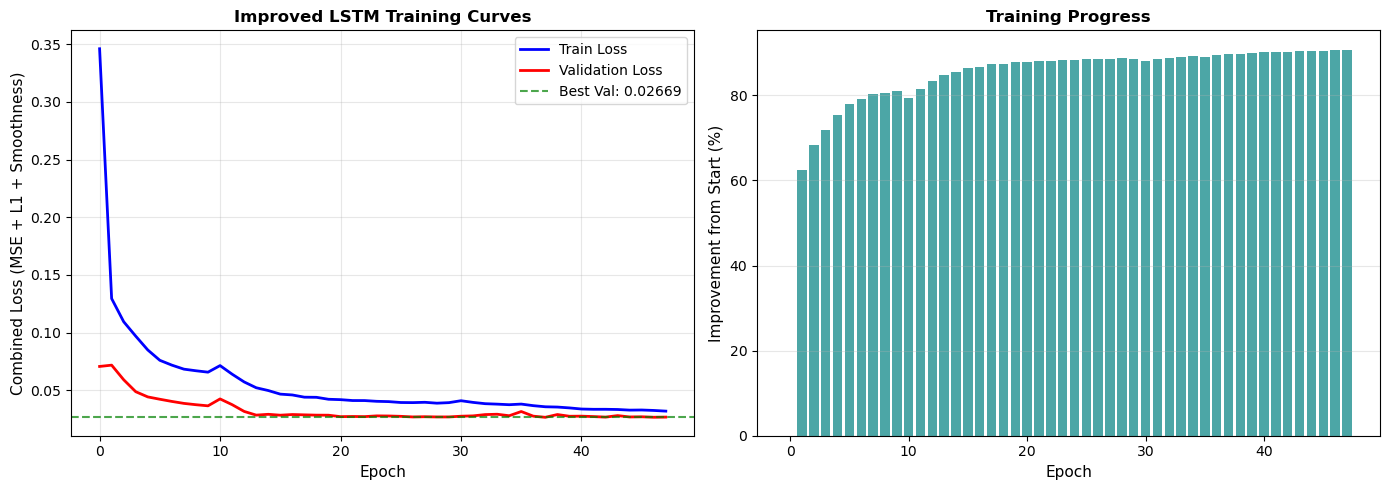


Training Summary
Initial Loss: 0.34594
Final Train Loss: 0.03204
Best Val Loss: 0.02669
Improvement: 92.3%


In [33]:
# Plot training curves with improvements visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax1 = axes[0]
ax1.plot(train_losses, label='Train Loss', color='blue', linewidth=2)
ax1.plot(val_losses, label='Validation Loss', color='red', linewidth=2)
ax1.axhline(y=min(val_losses), color='green', linestyle='--', alpha=0.7, label=f'Best Val: {min(val_losses):.5f}')
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Combined Loss (MSE + L1 + Smoothness)', fontsize=11)
ax1.set_title('Improved LSTM Training Curves', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Loss improvement over epochs
ax2 = axes[1]
improvement = [(train_losses[0] - t) / train_losses[0] * 100 for t in train_losses]
ax2.bar(range(len(improvement)), improvement, color='teal', alpha=0.7)
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Improvement from Start (%)', fontsize=11)
ax2.set_title('Training Progress', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Print summary stats
print(f"\n{'='*50}")
print(f"Training Summary")
print(f"{'='*50}")
print(f"Initial Loss: {train_losses[0]:.5f}")
print(f"Final Train Loss: {train_losses[-1]:.5f}")
print(f"Best Val Loss: {min(val_losses):.5f}")
print(f"Improvement: {(train_losses[0] - min(val_losses)) / train_losses[0] * 100:.1f}%")

## 6. Prediction & Visualization (Single Trajectory)

In [27]:
def predict_lstm(model, patient_data, num_samples=1):
    """
    Generate prediction(s) for a patient.
    
    patient_data: (seq_len, num_features) tensor or numpy array
    num_samples: if >1, adds small noise for pseudo-ensemble (dropout at inference)
    returns: (pred_len, num_features) or (num_samples, pred_len, num_features)
    """
    input_len = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    
    # Convert to tensor if needed
    if isinstance(patient_data, np.ndarray):
        patient_data = torch.tensor(patient_data, dtype=torch.float32)
    
    # Use only the input portion (first 42 hours)
    x = patient_data[:input_len].unsqueeze(0).to(device)  # (1, 42, 5)
    
    if num_samples == 1:
        model.eval()
        with torch.no_grad():
            prediction = model(x, teacher_forcing_ratio=0.0)
        return prediction.squeeze(0).cpu().numpy()  # (6, 5)
    else:
        # Monte Carlo Dropout for uncertainty estimation
        model.train()  # Keep dropout active
        predictions = []
        with torch.no_grad():
            for _ in range(num_samples):
                pred = model(x, teacher_forcing_ratio=0.0)
                predictions.append(pred.squeeze(0).cpu().numpy())
        return np.array(predictions)  # (num_samples, 6, 5)

In [28]:
# Pick a random patient
idx = np.random.randint(0, len(dataset))
x_sample, y_sample = dataset[idx]

# Get LSTM prediction
full_sequence = dataset.data_cache[idx]  # (48, 5)
lstm_prediction = predict_lstm(lstm_model, torch.tensor(full_sequence))

print(f"Input shape: {x_sample.shape}")
print(f"Target shape: {y_sample.shape}")
print(f"Prediction shape: {lstm_prediction.shape}")

Input shape: torch.Size([42, 5])
Target shape: torch.Size([6, 5])
Prediction shape: (6, 5)


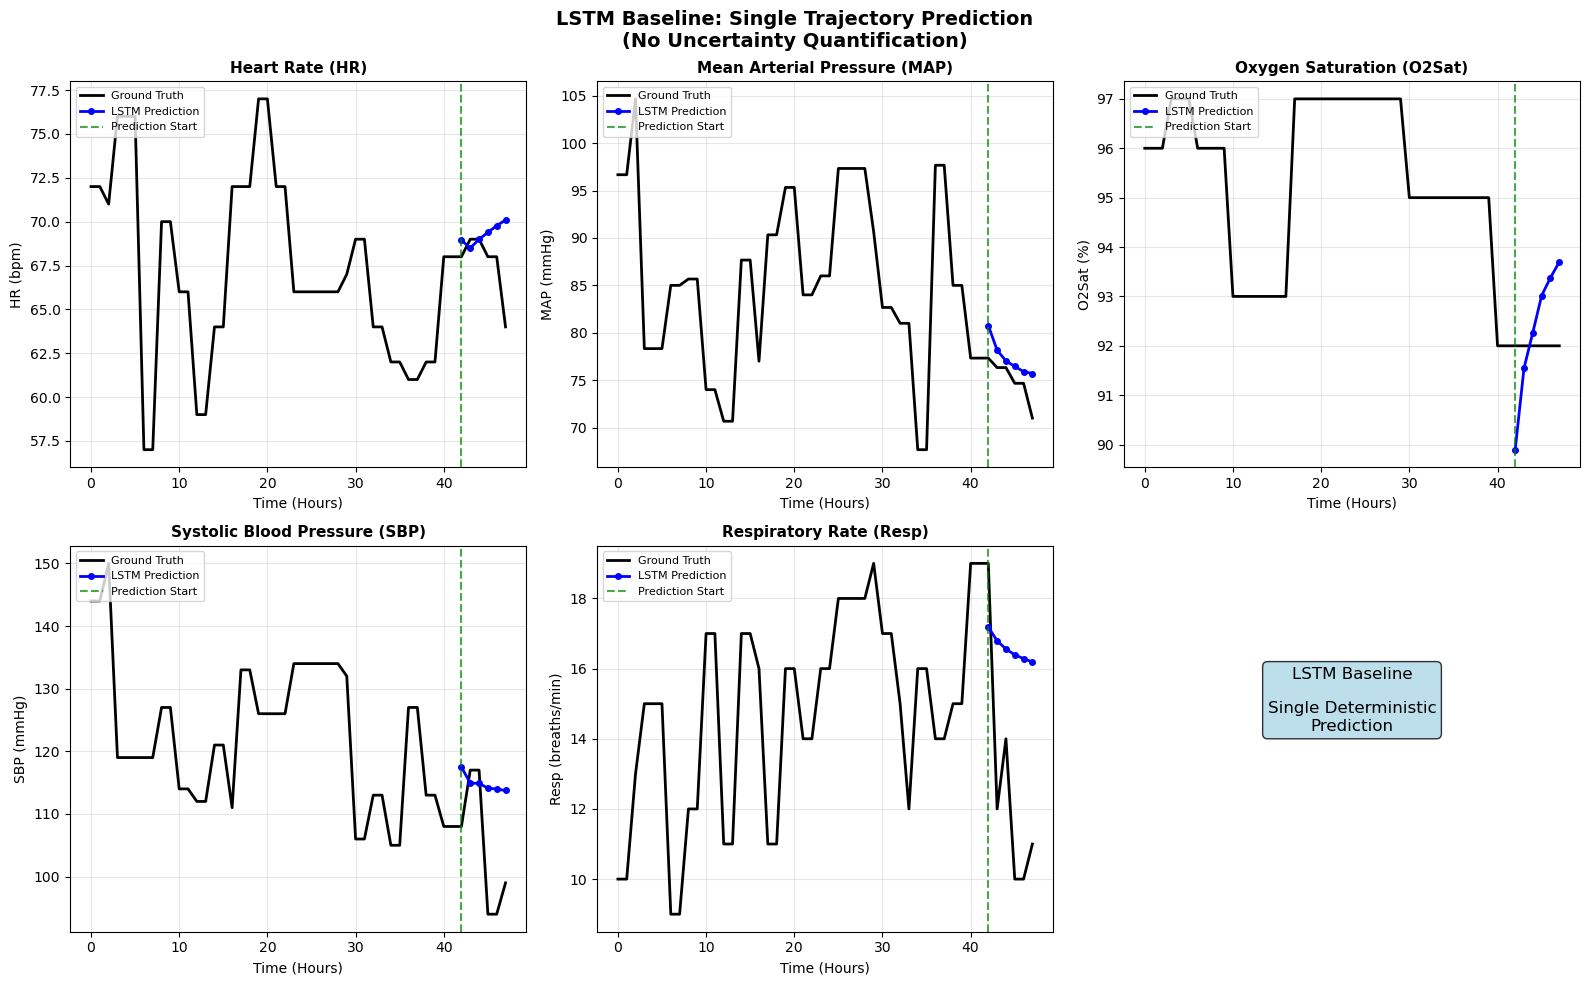

In [29]:
# Visualize LSTM prediction for all vitals
input_len = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
    ax = axes[vital_idx]
    info = VITAL_INFO[vital_key]
    scale = info['scale']
    
    # Full ground truth
    full_truth = full_sequence[:, vital_idx] * scale
    
    # LSTM prediction (only future part)
    pred = lstm_prediction[:, vital_idx] * scale
    
    # Plot ground truth (full sequence)
    ax.plot(range(CONFIG["SEQ_LEN"]), full_truth, 'k-', linewidth=2, label='Ground Truth')
    
    # Plot LSTM prediction (future part only)
    ax.plot(range(input_len, CONFIG["SEQ_LEN"]), pred, 'b-', linewidth=2, 
            label='LSTM Prediction', marker='o', markersize=4)
    
    # Prediction start line
    ax.axvline(x=input_len, color='green', linestyle='--', alpha=0.7, label='Prediction Start')
    
    ax.set_title(f"{info['name']} ({vital_key})", fontsize=11, fontweight='bold')
    ax.set_xlabel('Time (Hours)')
    ax.set_ylabel(f"{vital_key} ({info['unit']})")
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide 6th subplot
axes[5].axis('off')
axes[5].text(0.5, 0.6, "LSTM Baseline\n\nSingle Deterministic\nPrediction", 
             fontsize=12, ha='center', va='center', transform=axes[5].transAxes,
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

plt.suptitle("LSTM Baseline: Single Trajectory Prediction\n(No Uncertainty Quantification)", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Evaluate Model Performance

IMPROVED LSTM EVALUATION METRICS

📊 Per-Vital Performance:
----------------------------------------------------------------------
HR       | RMSE:  10.06 bpm          | MAE:   7.31 | Corr: 0.829
MAP      | RMSE:  11.79 mmHg         | MAE:   8.41 | Corr: 0.631
O2Sat    | RMSE:   5.15 %            | MAE:   3.63 | Corr: 0.181
SBP      | RMSE:  15.39 mmHg         | MAE:  11.63 | Corr: 0.781
Resp     | RMSE:   4.17 breaths/min  | MAE:   2.99 | Corr: 0.732

📈 Performance by Prediction Horizon:
----------------------------------------------------------------------
  Hour |       HR      MAP    O2Sat      SBP     Resp |  Avg RMSE
----------------------------------------------------------------------
   + 1  |     8.21    10.81     6.20    15.04     3.57 |     8.77
   + 2  |     9.60    10.10     5.03    15.03     3.69 |     8.69
   + 3  |    10.00    10.48     4.91    14.48     4.02 |     8.78
   + 4  |    10.41    10.83     4.84    16.00     4.97 |     9.41
   + 5  |    10.61    15.67     4.9

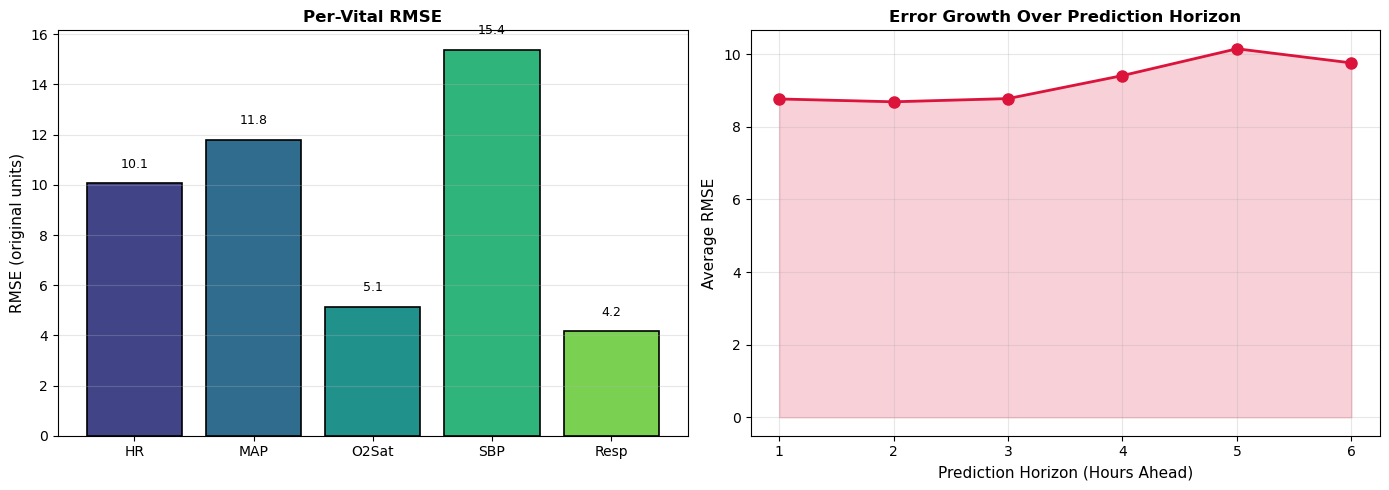

In [30]:
def evaluate_lstm(model, dataset, num_samples=300):
    """
    Comprehensive evaluation of LSTM with per-horizon and per-vital metrics.
    """
    model.eval()
    
    all_predictions = []
    all_targets = []
    
    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)
    
    for idx in indices:
        x, y = dataset[idx]
        x = x.unsqueeze(0).to(device)
        
        with torch.no_grad():
            pred = model(x, teacher_forcing_ratio=0.0).squeeze(0).cpu().numpy()
        
        all_predictions.append(pred)
        all_targets.append(y.numpy())
    
    all_predictions = np.array(all_predictions)  # (N, pred_len, features)
    all_targets = np.array(all_targets)
    
    # ==========================================
    # Per-Vital Metrics
    # ==========================================
    print("=" * 70)
    print("IMPROVED LSTM EVALUATION METRICS")
    print("=" * 70)
    print("\n📊 Per-Vital Performance:")
    print("-" * 70)
    
    results = []
    for i, vital in enumerate(CONFIG["VITALS"]):
        pred_vital = all_predictions[:, :, i].flatten()
        true_vital = all_targets[:, :, i].flatten()
        
        scale = VITAL_INFO[vital]['scale']
        
        mse = mean_squared_error(true_vital, pred_vital) * (scale ** 2)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(true_vital, pred_vital) * scale
        
        # Correlation
        corr = np.corrcoef(pred_vital, true_vital)[0, 1]
        
        results.append({
            'Vital': vital,
            'RMSE': rmse,
            'MAE': mae,
            'Correlation': corr,
            'Unit': VITAL_INFO[vital]['unit']
        })
        
        print(f"{vital:8} | RMSE: {rmse:6.2f} {VITAL_INFO[vital]['unit']:12} | MAE: {mae:6.2f} | Corr: {corr:.3f}")
    
    # ==========================================
    # Per-Horizon Metrics (how accuracy degrades over time)
    # ==========================================
    print("\n📈 Performance by Prediction Horizon:")
    print("-" * 70)
    print(f"{'Hour':>6} |", end="")
    for vital in CONFIG["VITALS"]:
        print(f" {vital:>8}", end="")
    print(" |  Avg RMSE")
    print("-" * 70)
    
    horizon_results = []
    for h in range(CONFIG["PRED_LEN"]):
        hour_rmse = []
        print(f"   +{h+1:2d}  |", end="")
        for i, vital in enumerate(CONFIG["VITALS"]):
            pred_h = all_predictions[:, h, i]
            true_h = all_targets[:, h, i]
            scale = VITAL_INFO[vital]['scale']
            rmse = np.sqrt(mean_squared_error(true_h, pred_h)) * scale
            hour_rmse.append(rmse)
            print(f" {rmse:8.2f}", end="")
        avg_rmse = np.mean(hour_rmse)
        print(f" | {avg_rmse:8.2f}")
        horizon_results.append({'Hour': h+1, 'Avg_RMSE': avg_rmse})
    
    # ==========================================
    # Visualization
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar chart of per-vital RMSE
    ax1 = axes[0]
    vitals = [r['Vital'] for r in results]
    rmses = [r['RMSE'] for r in results]
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(vitals)))
    bars = ax1.bar(vitals, rmses, color=colors, edgecolor='black', linewidth=1.2)
    ax1.set_ylabel('RMSE (original units)', fontsize=11)
    ax1.set_title('Per-Vital RMSE', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar, rmse in zip(bars, rmses):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                 f'{rmse:.1f}', ha='center', va='bottom', fontsize=9)
    
    # Line chart of RMSE degradation over horizon
    ax2 = axes[1]
    hours = [r['Hour'] for r in horizon_results]
    avg_rmses = [r['Avg_RMSE'] for r in horizon_results]
    ax2.plot(hours, avg_rmses, 'o-', color='crimson', linewidth=2, markersize=8)
    ax2.fill_between(hours, 0, avg_rmses, alpha=0.2, color='crimson')
    ax2.set_xlabel('Prediction Horizon (Hours Ahead)', fontsize=11)
    ax2.set_ylabel('Average RMSE', fontsize=11)
    ax2.set_title('Error Growth Over Prediction Horizon', fontsize=12, fontweight='bold')
    ax2.set_xticks(hours)
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return pd.DataFrame(results)

# Evaluate
metrics_df = evaluate_lstm(lstm_model, dataset)

## 8. Side-by-Side Comparison: LSTM vs Diffusion

Run this after training both models to compare them on the same patient.

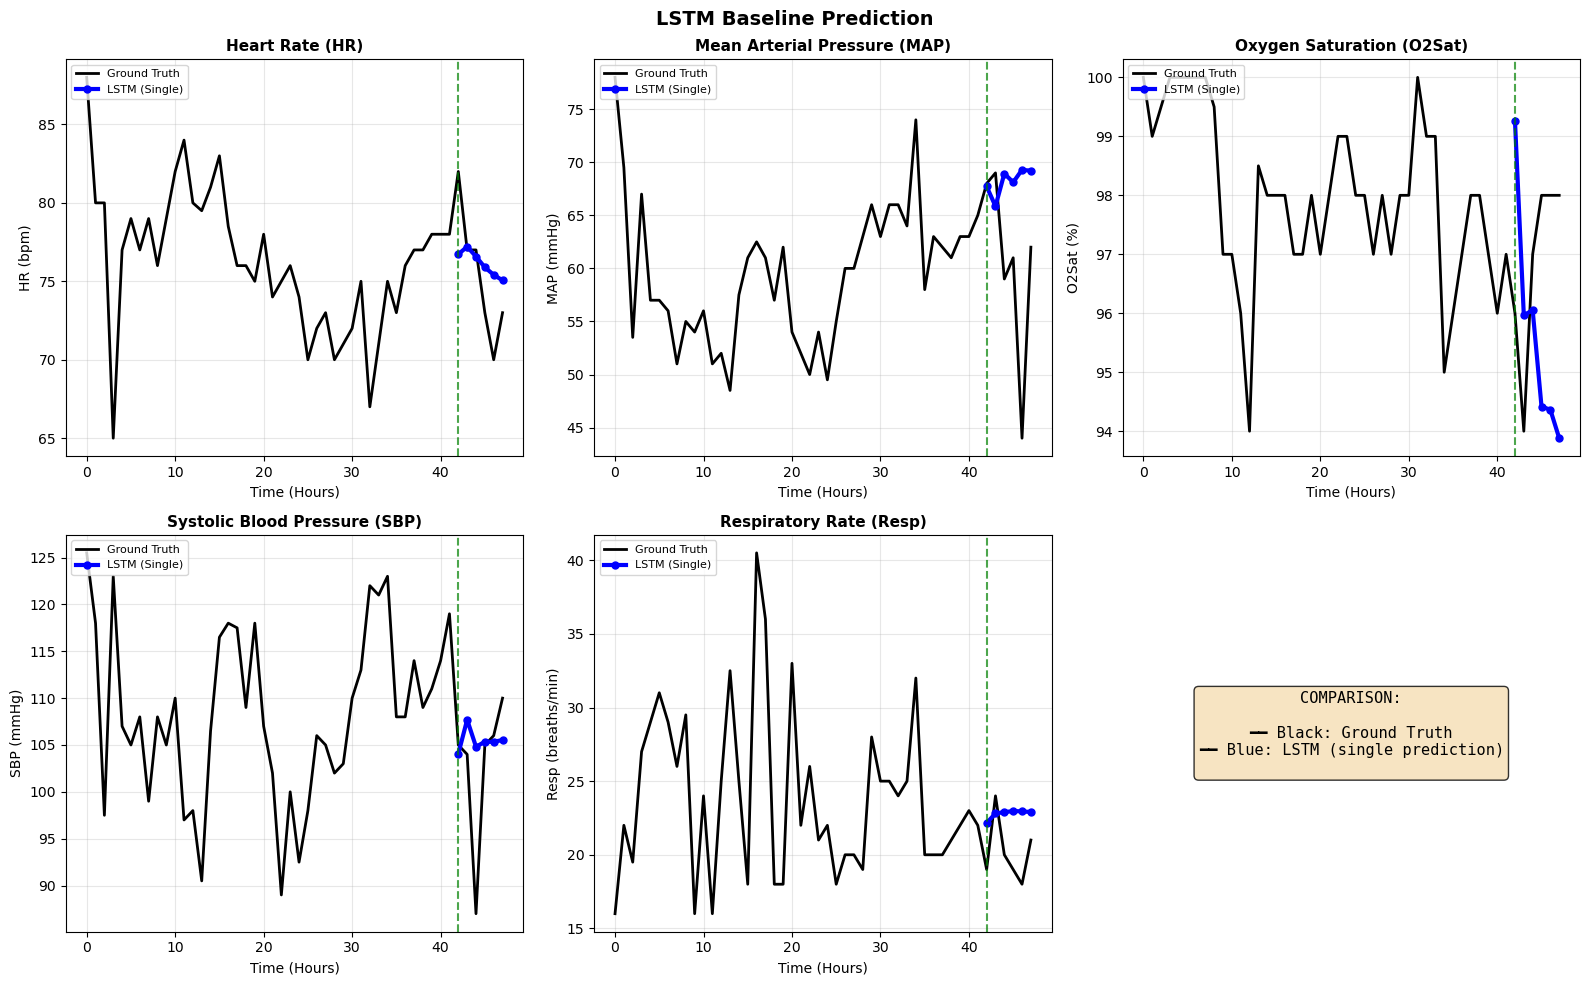

In [31]:
def compare_with_diffusion(lstm_model, patient_data, diffusion_futures=None):
    """
    Visual comparison of LSTM (single line) vs Diffusion (multiple trajectories).
    
    If diffusion_futures is None, only shows LSTM.
    diffusion_futures shape: (50, channels, seq_len) - from diffusion model
    """
    input_len = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]
    
    # Get LSTM prediction
    lstm_pred = predict_lstm(lstm_model, torch.tensor(patient_data))  # (6, 5)
    
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
        ax = axes[vital_idx]
        info = VITAL_INFO[vital_key]
        scale = info['scale']
        
        # Ground truth
        truth = patient_data[:, vital_idx] * scale
        ax.plot(range(CONFIG["SEQ_LEN"]), truth, 'k-', linewidth=2, label='Ground Truth')
        
        # LSTM prediction
        lstm_line = lstm_pred[:, vital_idx] * scale
        ax.plot(range(input_len, CONFIG["SEQ_LEN"]), lstm_line, 'b-', 
                linewidth=3, label='LSTM (Single)', marker='o', markersize=5)
        
        # Diffusion predictions (if provided)
        if diffusion_futures is not None:
            for i in range(min(50, len(diffusion_futures))):
                diff_line = diffusion_futures[i, vital_idx, input_len:] * scale
                ax.plot(range(input_len, CONFIG["SEQ_LEN"]), diff_line, 
                        'r-', alpha=0.1, linewidth=1)
            # Add one red line to legend
            ax.plot([], [], 'r-', alpha=0.5, label='Diffusion (50 samples)')
        
        ax.axvline(x=input_len, color='green', linestyle='--', alpha=0.7)
        ax.set_title(f"{info['name']} ({vital_key})", fontsize=11, fontweight='bold')
        ax.set_xlabel('Time (Hours)')
        ax.set_ylabel(f"{vital_key} ({info['unit']})")
        ax.legend(loc='upper left', fontsize=8)
        ax.grid(True, alpha=0.3)
    
    # Legend in 6th subplot
    axes[5].axis('off')
    comparison_text = (
        "COMPARISON:\n\n"
        "━━ Black: Ground Truth\n"
        "━━ Blue: LSTM (single prediction)\n"
    )
    if diffusion_futures is not None:
        comparison_text += "━━ Red: Diffusion (50 futures)\n\n"
        comparison_text += "LSTM gives ONE answer.\n"
        comparison_text += "Diffusion shows UNCERTAINTY."
    
    axes[5].text(0.5, 0.5, comparison_text, fontsize=11, ha='center', va='center',
                 transform=axes[5].transAxes, family='monospace',
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    title = "LSTM Baseline Prediction"
    if diffusion_futures is not None:
        title = "Comparison: LSTM (Blue) vs Diffusion Model (Red)"
    
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Run comparison (LSTM only for now)
sample_patient = dataset.data_cache[np.random.randint(len(dataset))]
compare_with_diffusion(lstm_model, sample_patient, diffusion_futures=None)

## 9. Key Takeaways: LSTM vs Diffusion

| Aspect | LSTM | Diffusion Model |
|--------|------|----------------|
| **Output** | Single trajectory | 50 possible futures |
| **Uncertainty** | ❌ None | ✅ Built-in |
| **Training Time** | ~5 min | ~15-30 min |
| **Inference Time** | ~1ms | ~500ms (50 samples) |
| **Clinical Use** | Point estimate only | Risk-aware decision support |

### When to use LSTM:
- Need fast inference
- Only need average prediction
- Resource constrained

### When to use Diffusion:
- Need uncertainty quantification
- High-stakes medical decisions
- Want to show range of possible outcomes

In [32]:
# Print comprehensive summary
print("\n" + "="*70)
print("IMPROVED LSTM MODEL SUMMARY")
print("="*70)

print("\n🏗️  Architecture Improvements:")
print(f"   • Bidirectional Encoder: ✓ (captures past & future context)")
print(f"   • Attention Mechanism: {CONFIG['USE_ATTENTION']}")
print(f"   • Layer Normalization: ✓ (training stability)")
print(f"   • Residual Connections: ✓ (skip connections)")
print(f"   • Multi-layer Output MLP: ✓")

print("\n📊 Model Configuration:")
print(f"   • Hidden Dim: {CONFIG['HIDDEN_DIM']}")
print(f"   • LSTM Layers: {CONFIG['NUM_LAYERS']}")
print(f"   • Dropout: {CONFIG['DROPOUT']}")
print(f"   • Parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")

print("\n🎯 Training Improvements:")
print(f"   • Optimizer: AdamW with weight decay ({CONFIG['WEIGHT_DECAY']})")
print(f"   • Scheduler: Cosine Annealing with Warm Restarts")
print(f"   • Teacher Forcing: {CONFIG['TEACHER_FORCING_RATIO']} (decaying)")
print(f"   • Loss: MSE + L1 + Smoothness Penalty")
print(f"   • Early Stopping: ✓ (patience=10)")

print(f"\n📈 Task:")
print(f"   • Input: {CONFIG['SEQ_LEN']-CONFIG['PRED_LEN']} hours of patient history")
print(f"   • Output: Predict next {CONFIG['PRED_LEN']} hours")
print(f"   • Vitals: {', '.join(CONFIG['VITALS'])}")

print(f"\n✅ Final Results:")
print(f"   • Final Train Loss: {train_losses[-1]:.5f}")
print(f"   • Best Val Loss: {min(val_losses):.5f}")
print(f"   • Epochs Trained: {len(train_losses)}")

print("\n" + "="*70)


IMPROVED LSTM MODEL SUMMARY

🏗️  Architecture Improvements:
   • Bidirectional Encoder: ✓ (captures past & future context)
   • Attention Mechanism: True
   • Layer Normalization: ✓ (training stability)
   • Residual Connections: ✓ (skip connections)
   • Multi-layer Output MLP: ✓

📊 Model Configuration:
   • Hidden Dim: 256
   • LSTM Layers: 3
   • Dropout: 0.3
   • Parameters: 6,068,648

🎯 Training Improvements:
   • Optimizer: AdamW with weight decay (1e-05)
   • Scheduler: Cosine Annealing with Warm Restarts
   • Teacher Forcing: 0.5 (decaying)
   • Loss: MSE + L1 + Smoothness Penalty
   • Early Stopping: ✓ (patience=10)

📈 Task:
   • Input: 42 hours of patient history
   • Output: Predict next 6 hours
   • Vitals: HR, MAP, O2Sat, SBP, Resp

✅ Final Results:
   • Final Train Loss: 0.03204
   • Best Val Loss: 0.02669
   • Epochs Trained: 48

